In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

De un proyecto sólo se conserva el diagrama de Gantt de inicios más tempranos que se adjunta (semanas). Cada flecha une el fin de una actividad con el inicio de otra que no puede empezar antes (prelación inmediata); las flechas rojas unen actividades críticas.

In [4]:
pregunta_1 = "1. Reconstruya el cuadro de prelaciones inmediatas y las duraciones a partir del diagrama. ¿Qué actividades son iniciales y cuáles finales? ¿Cómo se reconocen?  "
pregunta_2 = "2. Dibuje el grafo PERT con el mínimo número de actividades ficticias. ¿Por qué necesita ficticias el PERT si el Gantt no las necesita?  "
pregunta_3 = "3. Calcule el calendario con la librería y compruebe que reproduce el Gantt (inicios más tempranos) y el camino crítico marcado en rojo.  "
pregunta_4 = "4. Lea sobre el Gantt la holgura libre de cada actividad no crítica (hueco hasta su primera sucesora) y compárela con la calculada. ¿Se puede leer también la holgura total? ¿Qué haría falta?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Reconstruya el cuadro de prelaciones inmediatas y las duraciones a partir del diagrama. ¿Qué actividades son iniciales y cuáles finales? ¿Cómo se reconocen?  

2. Dibuje el grafo PERT con el mínimo número de actividades ficticias. ¿Por qué necesita ficticias el PERT si el Gantt no las necesita?  

3. Calcule el calendario con la librería y compruebe que reproduce el Gantt (inicios más tempranos) y el camino crítico marcado en rojo.  

4. Lea sobre el Gantt la holgura libre de cada actividad no crítica (hueco hasta su primera sucesora) y compárela con la calculada. ¿Se puede leer también la holgura total? ¿Qué haría falta?  

In [5]:
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 2       ),
    ('B'     , '---'      , 3       ),
    ('C'     , '---'      , 7       ),
    ('D'     , 'B'        , 4       ),
    ('E'     , 'A,D'      , 4       ),
    ('F'     , 'E'        , 1       ),
    ('G'     , 'C,E'      , 6       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
# (el cuadro completo no se muestra: el enunciado es el diagrama)

In [6]:
_proyecto = PredecessorTable.from_dataframe_of_strings(datos_enunciado, activity='activity', predecessor='predecessor').create_project()

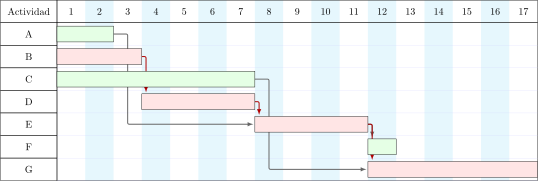

In [7]:
#| fig-cap: "Diagrama de Gantt del proyecto"
#| label: fig-ganttEnunciado
_g, _dibujo = _proyecto.gantt(datos_enunciado, 'duration', holguras=False, tikz=True, params=dict(inner_text=None, **GANTT_PARAMS))
pinta_tikz(_dibujo)

# Resolución

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Reconstruya el cuadro de prelaciones inmediatas y las duraciones a partir del diagrama. ¿Qué actividades son iniciales y cuáles finales? ¿Cómo se reconocen?  

La duración de cada actividad es la longitud de su barra. Sus predecesoras inmediatas son las actividades de las que recibe una flecha. Las iniciales no reciben ninguna flecha (y empiezan en la semana 0); las finales no emiten ninguna.

In [9]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
print('Iniciales:', ', '.join(sorted(prelaciones.start_activities)), '  Finales:', ', '.join(sorted(prelaciones.end_activities)))
datos_proyecto[['predecessor', 'duration']]

Iniciales: A, B, C   Finales: F, G


,predecessor,duration
activity,,
A,---,2
B,---,3
C,---,7
D,B,4
E,"A,D",4
F,E,1
G,"C,E",6


## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Dibuje el grafo PERT con el mínimo número de actividades ficticias. ¿Por qué necesita ficticias el PERT si el Gantt no las necesita?  

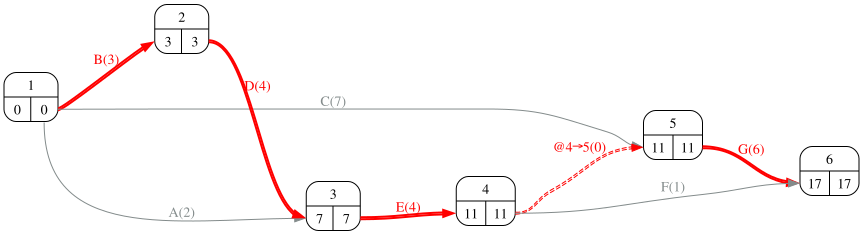

In [11]:
#| fig-cap: "Grafo PERT reconstruido, con tiempos y camino crítico"
#| label: fig-grafo
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [12]:
Markdown(f'''El PERT representa las actividades como arcos, y un arco sólo puede salir de un nodo: cuando dos actividades comparten *algunas* predecesoras pero no todas, hace falta una ficticia para no inventar prelaciones. El Gantt no tiene ese problema porque dibuja cada prelación como una flecha independiente. Este grafo necesita {len(proyecto.dummies)} ficticia(s).''')

El PERT representa las actividades como arcos, y un arco sólo puede salir de un nodo: cuando dos actividades comparten *algunas* predecesoras pero no todas, hace falta una ficticia para no inventar prelaciones. El Gantt no tiene ese problema porque dibuja cada prelación como una flecha independiente. Este grafo necesita 1 ficticia(s).

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Calcule el calendario con la librería y compruebe que reproduce el Gantt (inicios más tempranos) y el camino crítico marcado en rojo.  

In [14]:
#| tbl-cap: "Calendario calculado"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,5,2,7,5,5,5,2
B,0,0,3,3,0,0,0,3
C,0,4,7,11,4,4,4,7
D,3,3,7,7,0,0,0,4
E,7,7,11,11,0,0,0,4
F,11,16,12,17,5,5,5,1
G,11,11,17,17,0,0,0,6


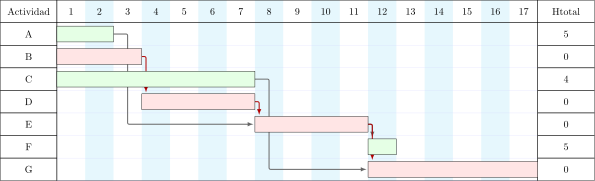

In [15]:
#| fig-cap: "Gantt calculado (coincide con el del enunciado; última columna: holgura total)"
#| label: fig-ganttCalculado
_g, _dibujo = proyecto.gantt(datos_proyecto, 'duration', holguras=True, tikz=True, params=dict(inner_text=None, **GANTT_PARAMS))
pinta_tikz(_dibujo)

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. Lea sobre el Gantt la holgura libre de cada actividad no crítica (hueco hasta su primera sucesora) y compárela con la calculada. ¿Se puede leer también la holgura total? ¿Qué haría falta?  

In [17]:
suc = {a: [b for b, ps in prelaciones.immediate_predecessor.items() if a in ps] for a in calendario.index}
fin = int(calendario['fin_mas_temprano'].max())
lectura = pd.DataFrame({
    'EF': calendario['fin_mas_temprano'],
    'mín ES de sus sucesoras (o fin)': [int(calendario.loc[suc[a], 'inicio_mas_temprano'].min()) if suc[a] else fin for a in calendario.index],
    'H_libre leída = hueco': [int((calendario.loc[suc[a], 'inicio_mas_temprano'].min() if suc[a] else fin) - calendario.loc[a, 'fin_mas_temprano']) for a in calendario.index],
    'H_libre calculada': calendario['H_libre'], 'H_total calculada': calendario['H_total']})
lectura

,EF,mín ES de sus sucesoras (o fin),H_libre leída = hueco,H_libre calculada,H_total calculada
activity,,,,,
A,2,7,5,5,5
B,3,3,0,0,0
C,7,11,4,4,4
D,7,7,0,0,0
E,11,11,0,0,0
F,12,17,5,5,5
G,17,17,0,0,0


La holgura libre es el hueco visible entre el fin de la barra y el inicio de la sucesora más próxima. La holgura total no se ve en un Gantt de inicios tempranos: requiere saber cuánto podrían retrasarse *también* las sucesoras, es decir, el paso hacia atrás (o el Gantt de inicios tardíos). Sólo coinciden cuando la sucesora es crítica.